# StreamView Analytics — Analisis Exploratorio de Datos (EDA)

**Evaluacion Parcial N°1 — ADY1104 Visualizacion de Datos (Duoc UC)**

Este notebook cubre los pasos **1. Entender el negocio**, **2. Preparar los datos**
y **3. Explorar y analizar** del flujo de trabajo del proyecto. El objetivo es
identificar patrones, tendencias y hallazgos en el catalogo de contenidos de
StreamView Analytics, y usar esos hallazgos para **justificar el diseno del
dashboard** (que tipo de grafico usar para cada pregunta de negocio).

La limpieza e integracion de los datos crudos se realiza por separado en
`src/data_prep.py`; este notebook parte directamente del dataset ya limpio.

> **Version EP3.** Notebook actualizado para la Evaluacion Parcial 3: taxonomia de generos unificada con tabla puente titulo-genero, ROI = ingresos / presupuesto, tabla de validacion de datos y graficos con periodo y tamano de muestra (codigo en `src/eda_charts.py`).

## Paso 1 — Entender el negocio

**Contexto organizacional.** StreamView Analytics es una plataforma internacional
de streaming digital que busca comprender el comportamiento de su catalogo de
contenidos (peliculas y series) para fortalecer decisiones de adquisicion,
produccion y promocion.

**Audiencia objetivo.** Gerente de Contenidos: necesita informacion clara y
accionable para decidir que contenidos adquirir, producir y promocionar — no
el detalle tecnico del analisis, sino los hallazgos que apoyan una decision.

**Objetivo de comunicacion.** Traducir el catalogo historico en una vision
accionable del desempeno del contenido (rating, popularidad, retorno
financiero) por genero, pais y tipo de contenido.

**Preguntas clave que debe responder este analisis:**

1. Que generos generan mejor desempeno (rating y popularidad)?
2. Que generos o paises conviene priorizar para produccion o adquisicion?
3. Que generos ofrecen mejor retorno financiero (ROI) por dolar invertido?
4. Que mercados concentran la mayor produccion de contenido?
5. Como ha evolucionado el desempeno del catalogo en el tiempo?

Estas cinco preguntas guian tanto el EDA de este notebook como el diseno del
dashboard (Paso 5).

## Paso 2 — Preparar los datos

La integracion de las dos fuentes originales (`netflix_movies_detailed_up_to_2025.csv`
y `netflix_tv_shows_detailed_up_to_2025.csv`), la limpieza y el calculo de variables
derivadas (genero/pais principal, ROI, indicador de confiabilidad del rating, etc.)
se realizan en **`src/data_prep.py`** (generos unificados en `src/genre_map.py`, KPIs en `src/kpis.py`). Aqui cargamos directamente el resultado ya
unificado y limpio para dedicar este notebook por completo a la exploracion.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import eda_charts as ec  # todos los graficos viven en src/eda_charts.py

df, bridge = ec.load_data()  # dataset limpio + tabla puente titulo-genero
print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Tabla puente titulo-genero: {bridge.shape[0]:,} filas ({bridge['content_id'].nunique():,} titulos)")
df.head()

Dataset cargado: 31,991 filas x 28 columnas
Tabla puente titulo-genero: 70,521 filas (31,991 titulos)


,show_id,type,title,director,cast,country,date_added,release_year,rating,genres,...,duration_min,year_added,decade,content_id,main_genre,main_country,financiero_valido,roi,rating_confiable,tipo
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,"Comedy, Adventure, Fantasy, Animation, Family",...,NaN,2010,2010,M_10192,Comedy,United States of America,True,4.561217,True,Película
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,"Action, Science Fiction, Adventure",...,NaN,2010,2010,M_27205,Action,United Kingdom,True,5.243941,True,Película
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,"Adventure, Fantasy",...,NaN,2010,2010,M_12444,Adventure,United Kingdom,True,3.817223,True,Película
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,"Animation, Family, Adventure",...,NaN,2010,2010,M_38757,Animation,United States of America,True,2.278699,True,Película
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,"Fantasy, Adventure, Animation, Family",...,NaN,2010,2010,M_10191,Fantasy,United States of America,True,2.999270,True,Película


In [2]:
df.dtypes

show_id                int64
type                     str
title                    str
director                 str
cast                     str
country                  str
date_added               str
release_year           int64
rating               float64
genres                   str
language                 str
description              str
popularity           float64
vote_count             int64
vote_average         float64
budget               float64
revenue              float64
seasons              float64
duration_min         float64
year_added             int64
decade                 int64
content_id               str
main_genre               str
main_country             str
financiero_valido       bool
roi                  float64
rating_confiable        bool
tipo                     str
dtype: object

### Calidad de datos: valores faltantes

Antes de explorar patrones, revisamos que variables tienen datos faltantes y en
que magnitud — esto determina que analisis son posibles y con que salvedades.

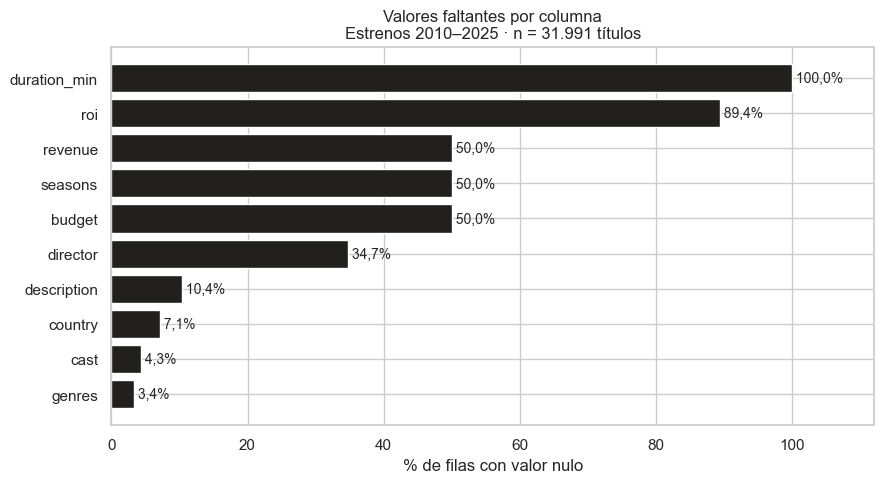

duration_min    100.0
roi              89.4
revenue          50.0
seasons          50.0
budget           50.0
director         34.7
description      10.4
country           7.1
cast              4.3
genres            3.4
dtype: float64

In [3]:
fig = ec.g_valores_faltantes(df)
plt.show()

nulos = df.drop(columns=["tipo"]).isna().sum()
(nulos[nulos > 0] / len(df) * 100).round(1).sort_values(ascending=False)

**Hallazgo:** `duration_min` (100% nulo, no aplica a peliculas en este dataset),
`roi` (89.4% nulo: solo existe para las 3.386 peliculas con datos financieros validos),
`budget`/`revenue` y `seasons` (50% nulo: cada campo aplica a un solo tipo de contenido).
Entre las columnas descriptivas, `director` tiene 34.7% de nulos, `description` 10.4%,
`country` 7.1%, `cast` 4.3% y `genres` 3.4%; solo `genres` y `country` se usan en el
dashboard y sus vacios se tratan como "Sin genero informado" / "Sin pais informado"
(ver la validacion mas abajo). Los nulos de `budget`, `revenue`, `seasons` y
`duration_min` son estructurales (por tipo de contenido), no errores de carga.

### Validacion de la integracion de fuentes

Trazabilidad completa de la limpieza (tabla `data/processed/validacion_datos.csv`, generada por
`src/data_prep.py`): filas antes y despues de cada paso, decisiones que afectan filas y unidades
de cada variable.

In [4]:
val = pd.read_csv(ROOT / "data" / "processed" / "validacion_datos.csv")
pd.set_option("display.max_colwidth", 100)
print("1. Filas por paso")
display(val[val["seccion"] == "1_filas_por_paso"][["metrica", "valor", "detalle"]].reset_index(drop=True))
print("3. Decisiones de limpieza")
display(val[val["seccion"] == "3_decisiones"][["metrica", "valor", "detalle"]].reset_index(drop=True))
print("4. Unidades")
display(val[val["seccion"] == "4_unidades"][["metrica", "valor"]].rename(columns={"metrica": "variable", "valor": "unidad"}).reset_index(drop=True))

1. Filas por paso


,metrica,valor,detalle
0,Peliculas (fuente 1),16000,netflix_movies_detailed_up_to_2025.csv
1,Series (fuente 2),16000,netflix_tv_shows_detailed_up_to_2025.csv
2,Union de ambas fuentes,32000,concat con columnas comunes
3,Duplicados eliminados,9,mismo show_id + titulo + tipo
4,Dataset limpio (una fila por titulo),31991,streamview_content_clean.csv
5,Filas de la tabla puente titulo-genero,70521,genero_puente.csv (un titulo puede tener varios generos)


3. Decisiones de limpieza


,metrica,valor,detalle
0,Titulos sin genero informado (Movie),107,"genres vacio en la fuente: se mantienen en conteos de catalogo, se excluyen de rankings por genero"
1,Titulos sin genero informado (TV Show),974,"genres vacio en la fuente: se mantienen en conteos de catalogo, se excluyen de rankings por genero"
2,Titulos sin pais informado,2261,se mantienen en el catalogo; se excluyen del ranking de paises
3,Titulos con rating confiable (>=20 votos),18371,solo ellos entran al rating promedio
4,Peliculas con financieros validos,3386,presupuesto >= 1.000.000 USD e ingresos > 0. de 16.000 peliculas
5,Peliculas con presupuesto/ingresos > 0 pero bajo el umbral,154,se descartan del analisis financiero


4. Unidades


,variable,unidad
0,budget / revenue,USD
1,vote_average / rating,escala 0-10 (promedio de votos TMDB; no es clasificacion etaria)
2,vote_count,numero de votos
3,popularity,indice relativo TMDB (sin unidad)
4,roi,"razon ingresos / presupuesto (sin unidad; 1,0 = recupera lo invertido)"
5,release_year / year_added,anio calendario
6,seasons,numero de temporadas (solo series)


**Decisiones de integracion.**

- **Generos:** las dos fuentes usan etiquetas distintas ("Action" vs "Action & Adventure", "Sci-Fi & Fantasy",
  "War & Politics", "Kids"). `src/genre_map.py` las lleva a una taxonomia comun y `genero_puente.csv` guarda una
  fila por cada genero de cada titulo, de modo que **un titulo cuenta una vez por cada genero** (la suma de los conteos
  por genero supera el total de titulos). El genero principal (`main_genre`) es el primero de la lista.
- **Sin genero informado:** 974 series y 107 peliculas llegan con el campo `genres` vacio (o "Unknown") desde la fuente:
  son titulos sin etiqueta asignada, no un error de carga. Se **mantienen** en los conteos de catalogo (totales, tipo, pais)
  y se **excluyen** de rankings y promedios por genero.
- **Claves:** `show_id` se repite entre peliculas y series (406 casos), por eso la clave unica es `content_id` (tipo + show_id).
- **Datos financieros:** un unico criterio (`financiero_valido`): pelicula con presupuesto >= 1 M USD e ingresos > 0 (3.386 titulos).

## Paso 3 — Explorar y analizar

Cada analisis de esta seccion sigue el mismo formato: **pregunta de negocio →
grafico → hallazgo → tipo de grafico recomendado para el dashboard**. Esta
ultima columna es la que justifica, mas adelante, las decisiones de diseno del
dashboard en Power BI.

### 3.1 Distribucion de `vote_count` — justificando el umbral de confiabilidad

**Pregunta:** cuantos votos necesita un titulo para que su rating promedio sea
representativo? Usamos esto para definir el filtro `rating_confiable` (>=20 votos)
aplicado en el resto del proyecto.

**Por que histograma:** es el grafico estandar para visualizar la forma de la
distribucion de una variable continua y decidir un punto de corte.

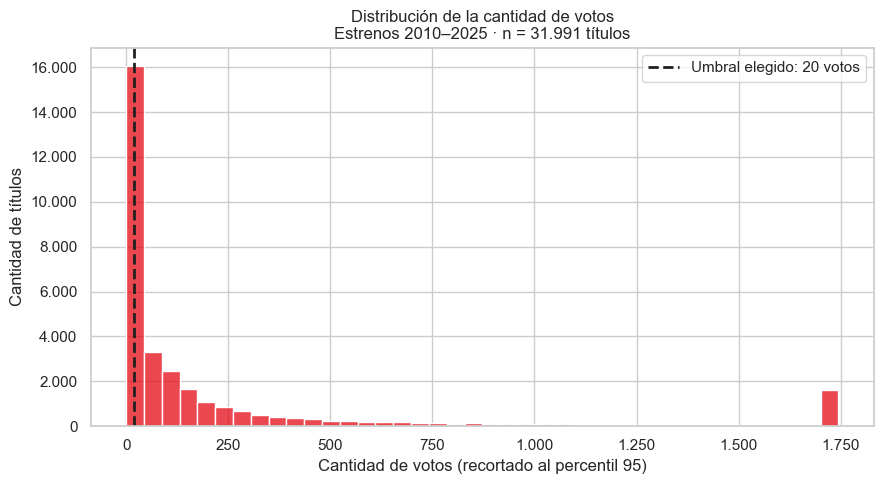

% de titulos con menos de 20 votos: 42.6%


In [5]:
fig = ec.g_distribucion_votos(df)
plt.show()

print(f"% de titulos con menos de 20 votos: {(df['vote_count'] < 20).mean()*100:.1f}%")

**Hallazgo:** una parte importante del catalogo tiene muy pocos votos. El corte
en 20 votos excluye los ratings menos confiables sin descartar una porcion
excesiva del catalogo. Este filtro se aplica en todos los analisis de rating
del proyecto (notebook, informe y dashboard).

### 3.2 Distribucion general del rating (`vote_average`)

**Pregunta:** el rating se concentra en algun rango? Es simetrico o sesgado?

**Por que histograma:** permite ver la forma completa de la distribucion (no
solo el promedio), relevante para decidir si el dashboard debe mostrar
promedio, mediana o ambos.

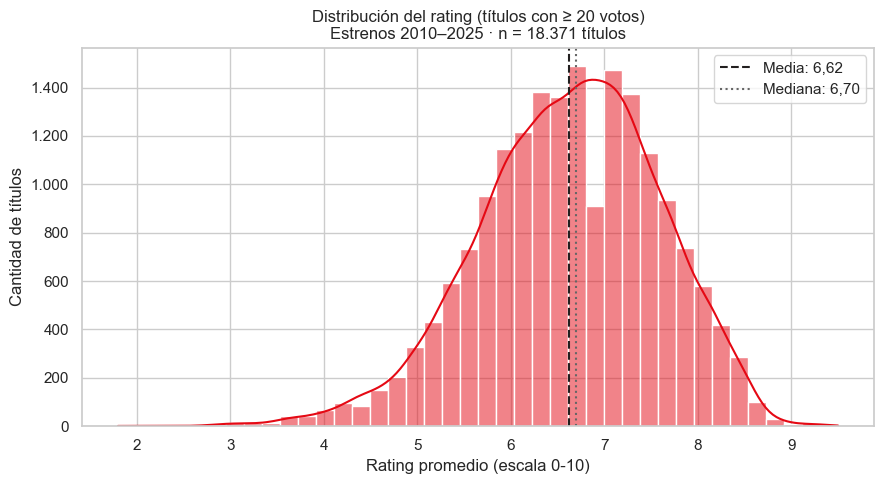

In [6]:
fig = ec.g_distribucion_rating(df)
plt.show()

**Hallazgo:** distribucion razonablemente simetrica, levemente concentrada
entre 6 y 8, sin grandes outliers. Media y mediana estan cerca, por lo que el
promedio es una metrica adecuada para el dashboard (no hace falta usar
mediana para evitar distorsion por outliers, a diferencia del ROI financiero).

### 3.3 Composicion del catalogo: Peliculas vs Series

**Pregunta:** el catalogo esta balanceado entre peliculas y series?

**Por que circular (pie):** es apropiado unicamente porque son 2 categorias
que suman el 100% del total — con mas de 2-3 categorias dejamos de usar pie
en el resto del analisis (ver 3.7, donde 10 generos se muestran en barras,
no en un pie ilegible).

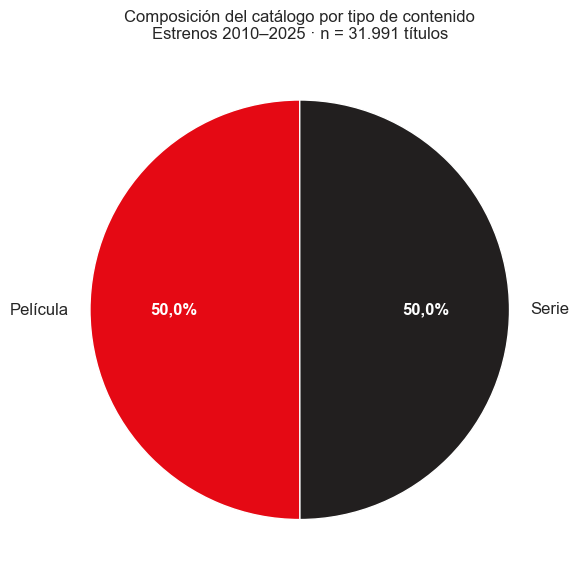

tipo
Película    16000
Serie       15991
Name: count, dtype: int64

In [7]:
fig = ec.g_mix_tipo(df)
plt.show()

df["tipo"].value_counts()

### 3.4 Volumen de titulos por ano de estreno y tipo

**Pregunta:** ha crecido el catalogo con el tiempo?

**Por que barras:** comparar una cantidad discreta (titulos) entre categorias
ordenadas (anos).

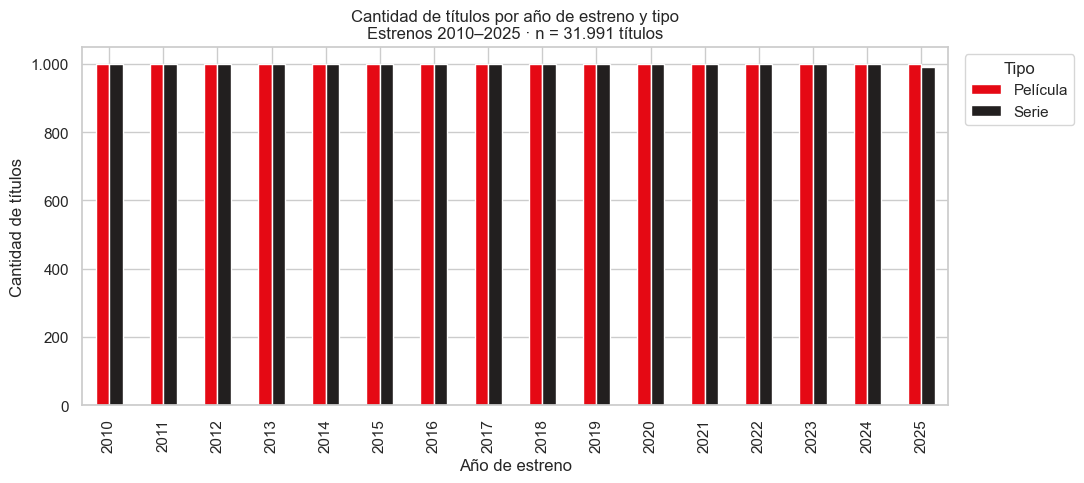

tipo,Película,Serie
count,16.0,16.0000
mean,1000.0,999.4375
std,0.0,2.2500
min,1000.0,991.0000
25%,1000.0,1000.0000
50%,1000.0,1000.0000
75%,1000.0,1000.0000
max,1000.0,1000.0000


In [8]:
fig = ec.g_volumen_anio(df)
plt.show()

df[df["release_year"].between(2010, 2025)].groupby(["release_year", "tipo"]).size().unstack().describe()

**Hallazgo (importante para el dashboard):** el volumen es practicamente
**identico** ano a ano (~1.000 peliculas y ~1.000 series entre 2010 y 2025).
Esto indica que el dataset es una **muestra estratificada** del proveedor, no
el volumen real historico de estrenos de la plataforma. Por eso, en el resto
del proyecto (incluido el dashboard), el analisis de tendencia temporal se
enfoca en **desempeno** (rating, popularidad) — donde si hay variacion real —
y no en volumen de estrenos, que seria enganoso.

### 3.5 Evolucion del rating promedio por ano de estreno

**Pregunta:** el desempeno del catalogo mejora o empeora con el tiempo?

**Por que lineas:** es el grafico estandar para tendencias continuas en el
tiempo, y permite comparar dos series (Movie vs TV Show) en el mismo eje.
**Justificacion para el dashboard:** este mismo grafico de lineas se usa en
Power BI para responder la pregunta 5 (evolucion del desempeno).

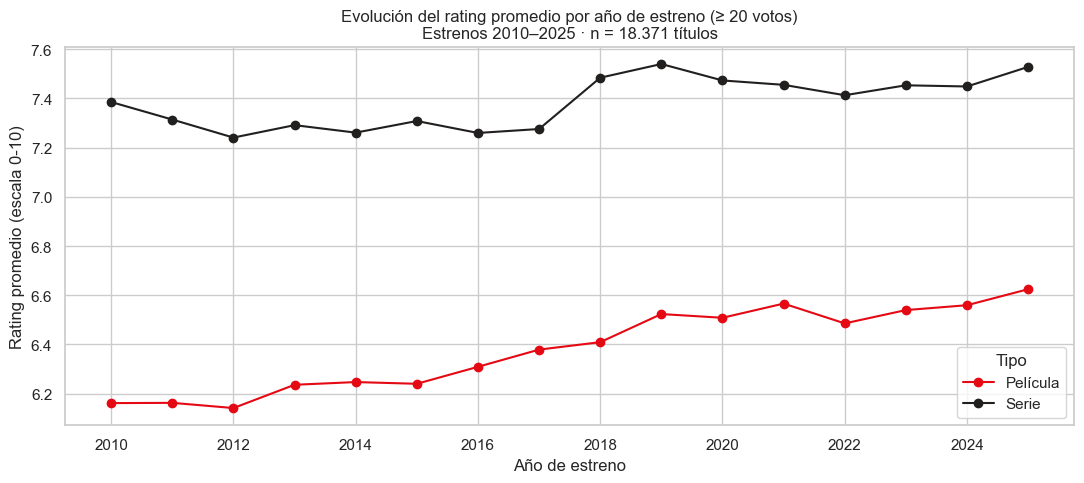

Rating promedio peliculas 2010: 6.16 -> 2025: 6.62
Rating promedio series 2010: 7.39 -> 2025: 7.53


In [9]:
fig = ec.g_evolucion_rating(df)
plt.show()

evol = df[df["rating_confiable"]].groupby(["release_year", "tipo"])["vote_average"].mean().unstack()
print(f"Rating promedio peliculas 2010: {evol.loc[2010, 'Película']:.2f} -> 2025: {evol.loc[2025, 'Película']:.2f}")
print(f"Rating promedio series 2010: {evol.loc[2010, 'Serie']:.2f} -> 2025: {evol.loc[2025, 'Serie']:.2f}")

**Hallazgo:** el rating de las peliculas mejora de forma sostenida (~6.16 a
~6.62); el de las series se mantiene estable y consistentemente mas alto
(7.2-7.5) durante todo el periodo.

### 3.6 Distribucion del rating por tipo de contenido (boxplot)

**Pregunta:** la diferencia entre Movie y TV Show que vimos en el promedio, se
sostiene al ver toda la distribucion (no solo el promedio)?

**Por que boxplot:** muestra mediana, dispersion y outliers de golpe — mejor
que una sola barra de promedio cuando queremos comparar la distribucion
completa entre 2 grupos.

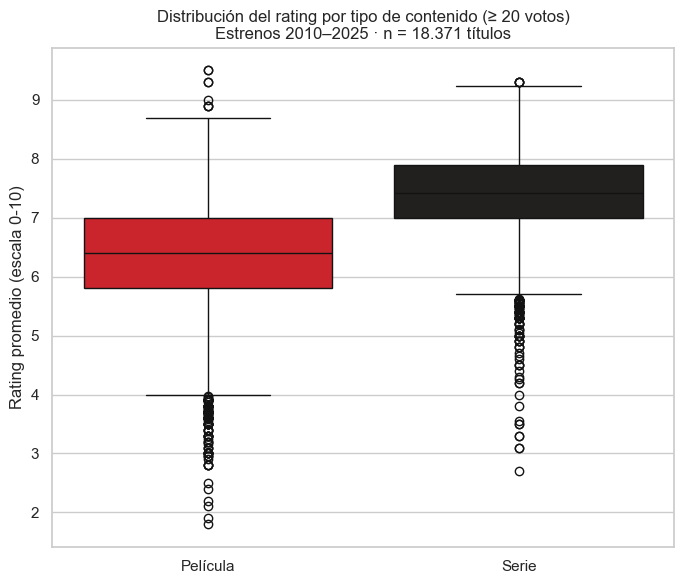

In [10]:
fig = ec.g_rating_por_tipo(df)
plt.show()

**Hallazgo:** confirma el patron del grafico de lineas — las series tienen una
mediana de rating mas alta y una distribucion mas concentrada (menos
dispersion) que las peliculas.

### 3.7 Volumen de titulos por genero

**Pregunta:** que generos concentran el catalogo?

**Nota:** los conteos por genero usan la tabla puente: un titulo con varios generos cuenta una vez en cada uno.

**Por que barras horizontales (y no pie):** con 10+ categorias, un grafico
circular se vuelve ilegible; barras horizontales ordenadas permiten comparar
magnitudes y leer las etiquetas de genero completas.

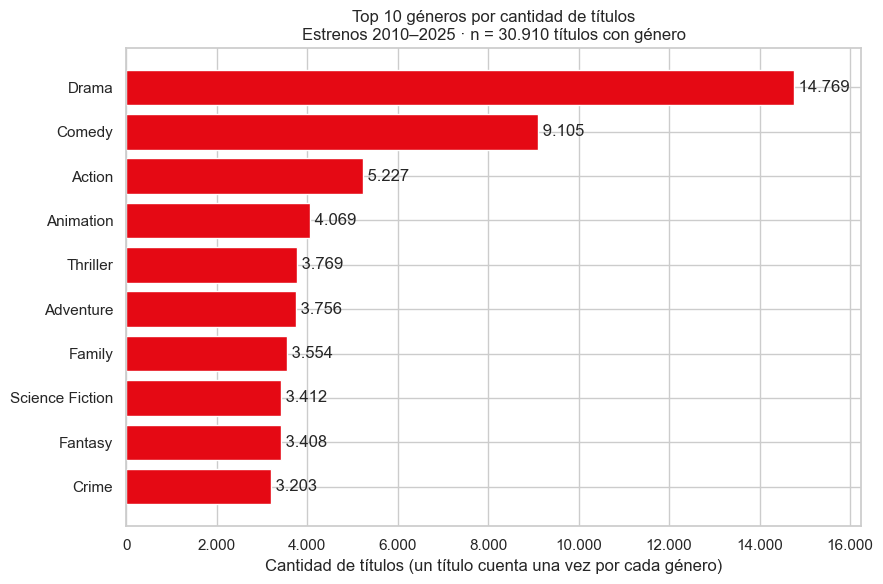

In [11]:
fig = ec.g_top_generos(df, bridge)
plt.show()

### 3.8 Rating promedio por genero

**Pregunta:** los generos con mas volumen son tambien los mejor evaluados?

**Por que barras agrupadas:** comparamos una metrica cuantitativa (rating)
entre categorias (genero) y sub-categorias (tipo de contenido) a la vez.

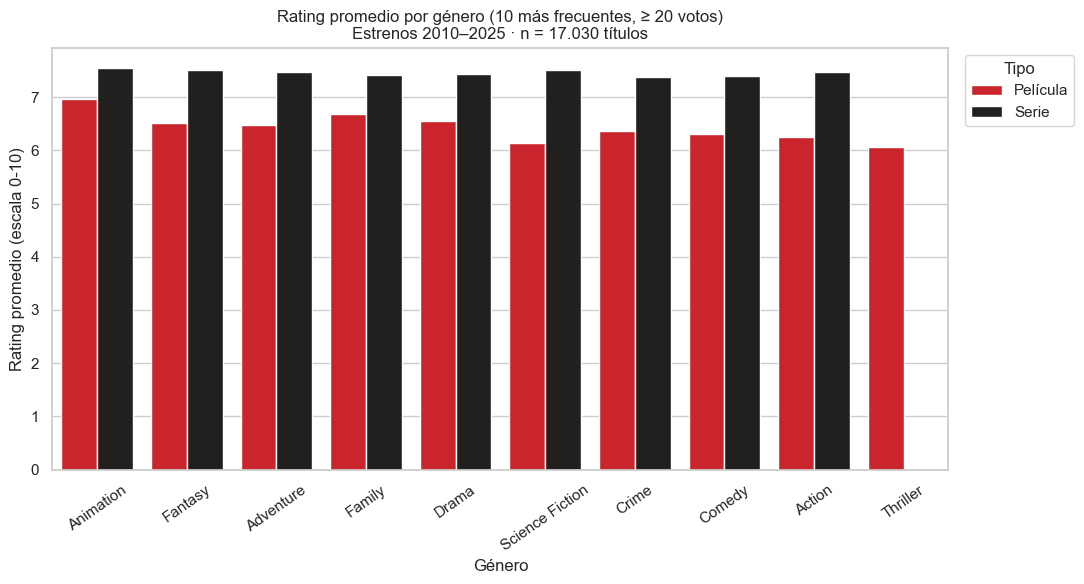

In [12]:
fig = ec.g_rating_por_genero(df, bridge)
plt.show()

**Hallazgo:** no — Animacion lidera el rating promedio (7.24) pese a tener menos
volumen que Drama o Comedia, y Drama/Comedia quedan en la mitad de la tabla. Thriller
es el mas bajo (6.06) y solo aparece en peliculas: la fuente de series no tiene la
etiqueta "Thriller". Esto es un hallazgo clave para las recomendaciones de negocio
(priorizar calidad/nicho sobre volumen).

### 3.9 Correlacion entre variables numericas

**Pregunta:** que variables se mueven juntas? Por ejemplo, mas votos implica
mas popularidad? Presupuesto mayor implica mejor rating?

**Por que heatmap de correlacion:** es la forma estandar de resumir muchas
relaciones bivariadas a la vez, antes de elegir que pares explorar en detalle
con un scatter (siguiente grafico).

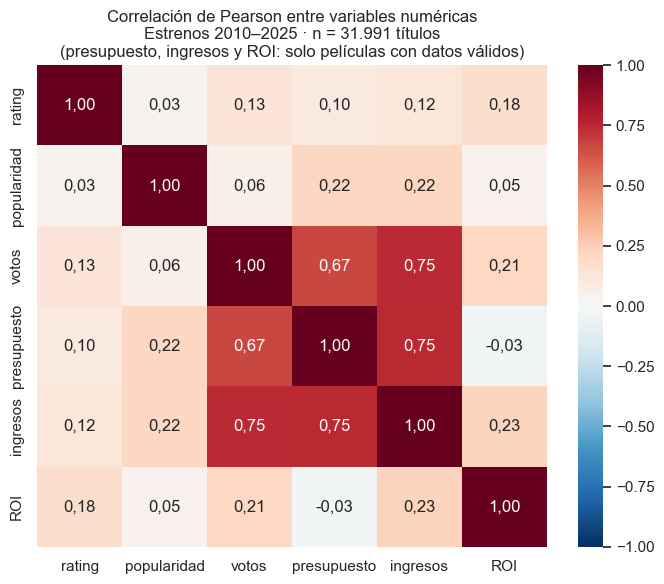

Rating vs popularidad: Spearman 0.21 | Pearson 0.03


In [13]:
fig = ec.g_correlacion(df)
plt.show()

pearson, spearman = ec.correlacion_rating_popularidad(df)
print(f"Rating vs popularidad: Spearman {spearman:.2f} | Pearson {pearson:.2f}")

**Hallazgo:** las correlaciones lineales (Pearson) son en general bajas. `vote_count` y `popularity` practicamente no se correlacionan (0.06) pese a que ambas suelen asumirse como medidas de "interes" del publico — son cosas distintas. Las correlaciones mas altas del set son `budget` con `revenue` y `vote_count` con `revenue` (ambas 0.75), esperables porque las peliculas grandes concentran presupuesto, votos e ingresos. El rating se relaciona de forma debil con todo: 0.03 con popularidad y 0.10-0.18 con las variables financieras — un presupuesto alto no compra buen rating, y un buen rating tampoco garantiza, por si solo, un `r` de Pearson alto con la popularidad (ver el matiz importante en el grafico siguiente).

### 3.10 Relacion entre rating y popularidad

**Pregunta:** los titulos mejor evaluados son tambien los mas populares?

**Por que dispersion (scatter):** es el grafico adecuado para explorar la
relacion entre dos variables cuantitativas continuas a nivel de titulo
individual (no agregado).

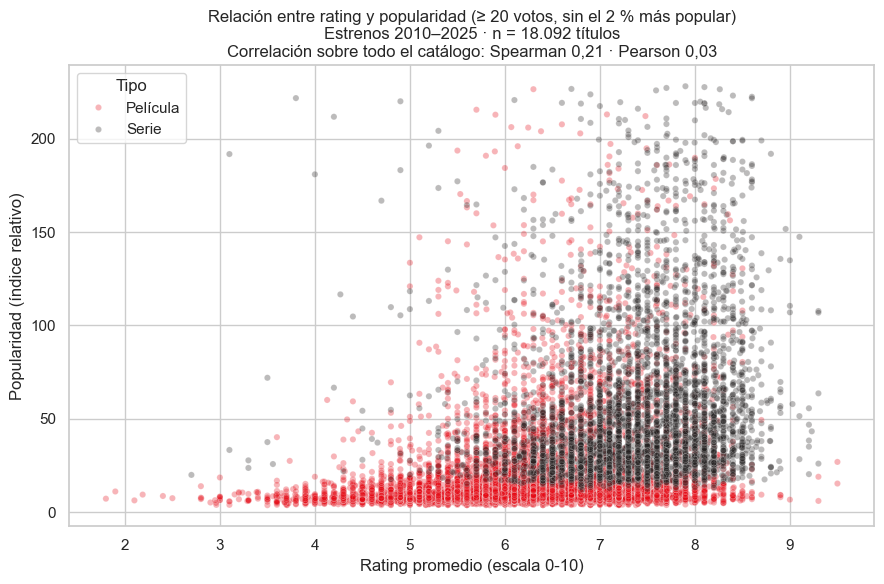

Rating vs popularidad (todo el catalogo): Spearman 0.21 | Pearson 0.03


In [14]:
fig = ec.g_popularidad_vs_rating(df)
plt.show()

pearson, spearman = ec.correlacion_rating_popularidad(df)
print(f"Rating vs popularidad (todo el catalogo): Spearman {spearman:.2f} | Pearson {pearson:.2f}")

**Hallazgo:** la relacion entre rating y popularidad es **positiva debil (Spearman 0.21; Pearson 0.03)**. El coeficiente de Pearson es casi nulo, pero el grafico de dispersion SI muestra un patron real: por debajo de rating ~5 la popularidad esta uniformemente baja (un "piso"), mientras que por sobre rating ~6 aparecen los valores de popularidad mas altos (un "techo" que sube). Es decir, buen rating no garantiza alta popularidad, pero rating bajo si limita el techo de popularidad. Que Spearman (relaciones monotonas, no solo lineales) sea mayor que Pearson confirma que la relacion existe pero no es lineal. Este es un buen ejemplo de por que el EDA visual (scatter) es necesario ademas de un coeficiente de correlacion: un analisis que se quedara solo con el numero (0.03) habria concluido, erroneamente, que no existe relacion alguna.

### 3.11 Distribucion geografica del catalogo

**Pregunta:** que paises concentran la produccion?

**Por que barras horizontales (y mapa en el dashboard):** en el notebook,
barras horizontales son suficientes y precisas para comparar magnitudes. En
el dashboard interactivo usaremos ademas un **mapa** (choropleth/burbujas),
porque ahi el objetivo es la percepcion espacial inmediata para una audiencia
ejecutiva, no la lectura de valores exactos.

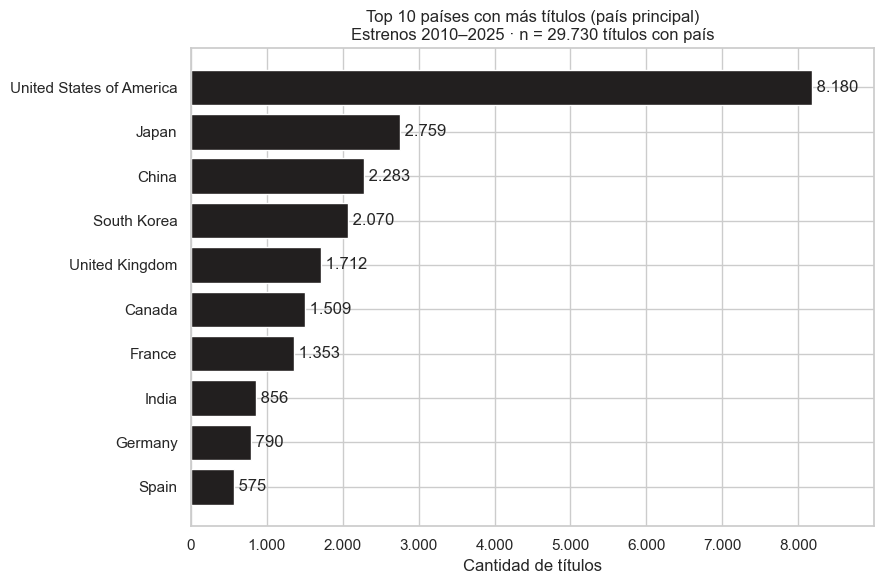

In [15]:
fig = ec.g_top_paises(df)
plt.show()

### 3.12 Presupuesto vs. Ingresos (peliculas con datos financieros)

**Pregunta:** mas presupuesto garantiza mas ingresos?

**Por que dispersion log-log:** presupuesto e ingresos tienen escalas muy
amplias (miles a cientos de millones); la escala logaritmica evita que un
puñado de peliculas de gran presupuesto dominen visualmente el grafico.

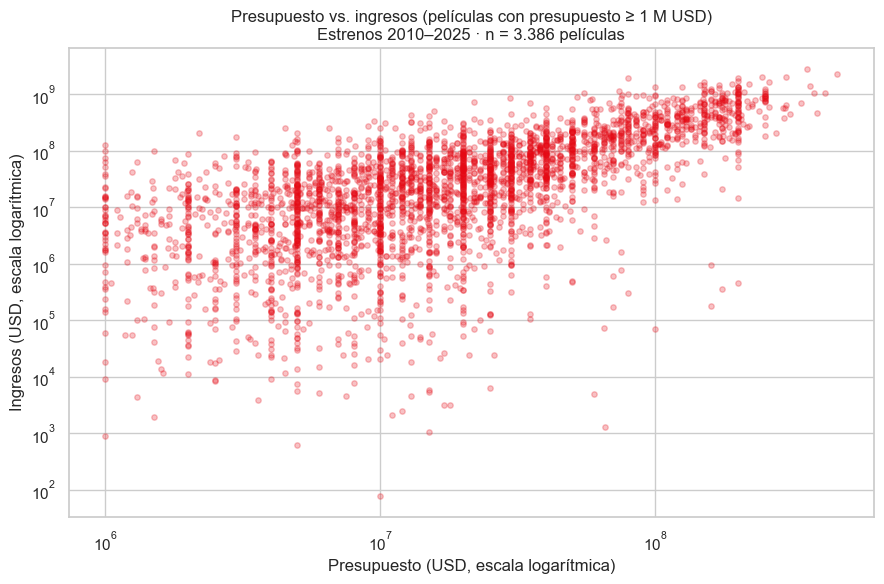

Peliculas con datos financieros validos (>=1M USD): 3,386


In [16]:
fig = ec.g_presupuesto_ingresos(df)
plt.show()

print(f"Peliculas con datos financieros validos (>=1M USD): {df['financiero_valido'].sum():,}")

**Hallazgo:** hay una relacion positiva pero con mucha dispersion — varias
peliculas de presupuesto bajo/medio logran ingresos altos, y viceversa. Esto
motiva mirar el **ROI** (retorno relativo al presupuesto) en vez de solo el
ingreso absoluto, que es lo que se analiza a continuacion.

### 3.13 ROI por genero (peliculas con presupuesto >= 1M USD)

**Definicion:** ROI = ingresos / presupuesto (1.0 = la pelicula recupera lo invertido; 2.0 = ingresa el doble).

**Pregunta:** que generos generan mejor retorno financiero relativo?

**Por que boxplot (y no barras de promedio):** el ROI tiene outliers extremos
(peliculas de bajo presupuesto con ingresos desproporcionados). Un promedio se
distorsiona con esos casos; el boxplot muestra la mediana real y la
dispersion, evitando conclusiones enganosas.

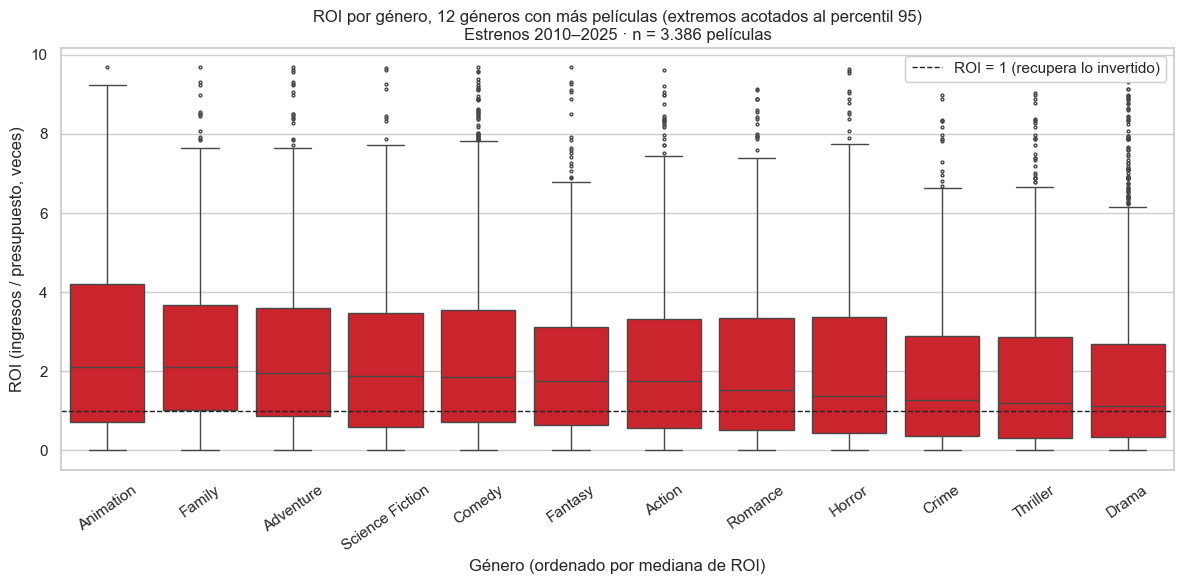

ROI mediano de las 3,386 peliculas con datos validos: 1.68x


,count,median
genero,,
Animation,280,2.29
Family,385,2.17
Horror,420,2.13
Adventure,697,2.02
Comedy,1107,2.02


In [17]:
fig = ec.g_roi_genero(df, bridge)
plt.show()

fin = df[df["financiero_valido"]]
print(f"ROI mediano de las {len(fin):,} peliculas con datos validos: {fin['roi'].median():.2f}x")
g = bridge[bridge["content_id"].isin(fin["content_id"])].merge(fin[["content_id", "roi"]], on="content_id")
med = g.groupby("genero")["roi"].agg(["count", "median"])
med[med["count"] >= 30].sort_values("median", ascending=False).round(2).head(5)

**Hallazgo:** Animacion (2.29x), Familia (2.17x) y Horror (2.13x) tienen las medianas de ROI mas altas; Drama (1.23x), Crime (1.33x) y Thriller (1.34x) —pese a concentrar mas presupuesto— tienen las mas bajas entre los generos grandes. La mediana global es 1.68x. Un titulo con varios generos cuenta en cada uno (tabla puente).

### 3.14 Composicion del catalogo por genero (treemap)

**Pregunta:** que proporcion del catalogo representa cada genero?

**Por que treemap:** muestra la composicion de un total con muchas categorias (23 generos) sin el problema
de un circular con demasiadas porciones: el area de cada rectangulo es proporcional a su cantidad de titulos.

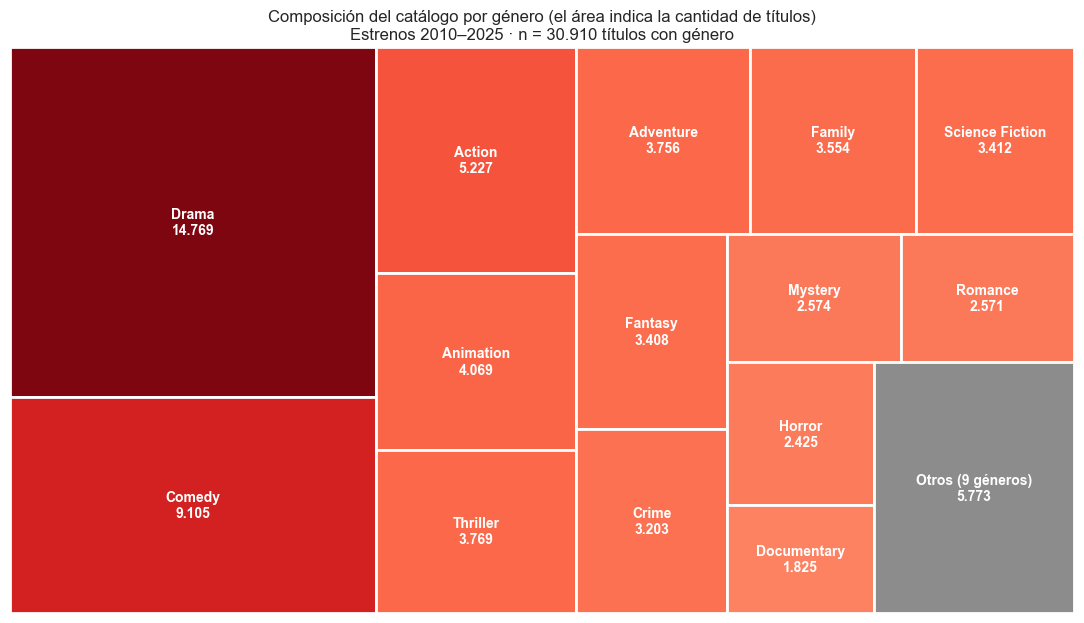

In [18]:
fig = ec.g_treemap_generos(df, bridge)
plt.show()

**Hallazgo:** Drama (14.769) y Comedia (9.105) concentran el 34% de las asignaciones de genero; los 9 generos
menos frecuentes suman 5.773 titulos. Un titulo cuenta en cada uno de sus generos (tabla puente).

### 3.15 Evolucion de la popularidad por ano de estreno (areas)

**Pregunta:** como ha cambiado el interes por los titulos segun su ano de estreno?

**Por que grafico de areas:** destaca la magnitud de una serie a lo largo del tiempo y permite comparar dos
series (pelicula y serie) en un mismo eje.

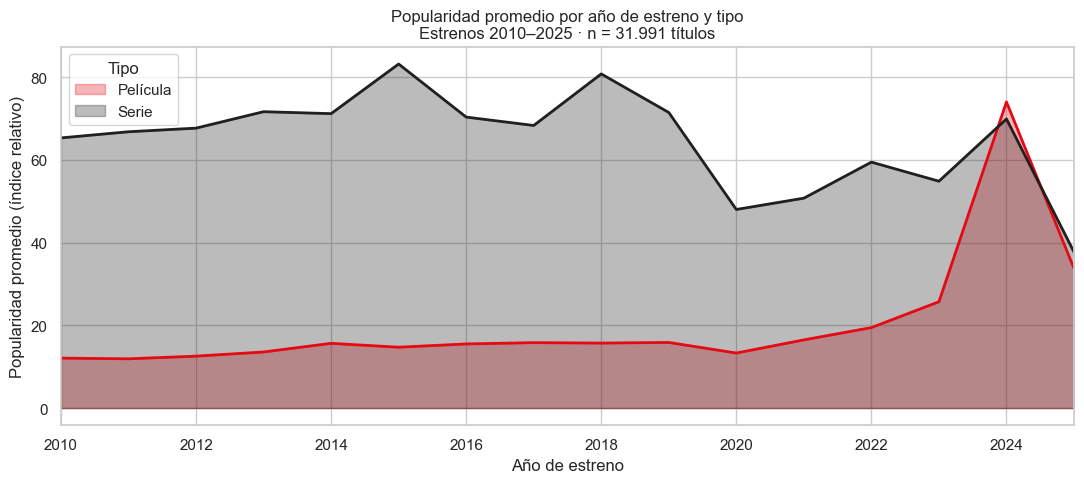

In [19]:
fig = ec.g_area_popularidad(df)
plt.show()

**Hallazgo:** las series tienen una popularidad promedio mucho mayor que las peliculas hasta 2023 (48-83 frente
a 12-26); en 2024 ambas convergen (~70-74) y en 2025 caen (~34-38), probablemente porque los titulos mas
recientes acumulan menos interaccion. La popularidad es un indice relativo, no una cantidad de reproducciones.

### 3.16 Directores y actores con mayor presencia

**Pregunta:** que directores y actores aparecen con mayor frecuencia en el catalogo?

**Por que barras horizontales:** permiten leer nombres largos y comparar cantidades. Los campos traen listas
separadas por coma, por lo que se cuenta cada persona en cada titulo en que participa.

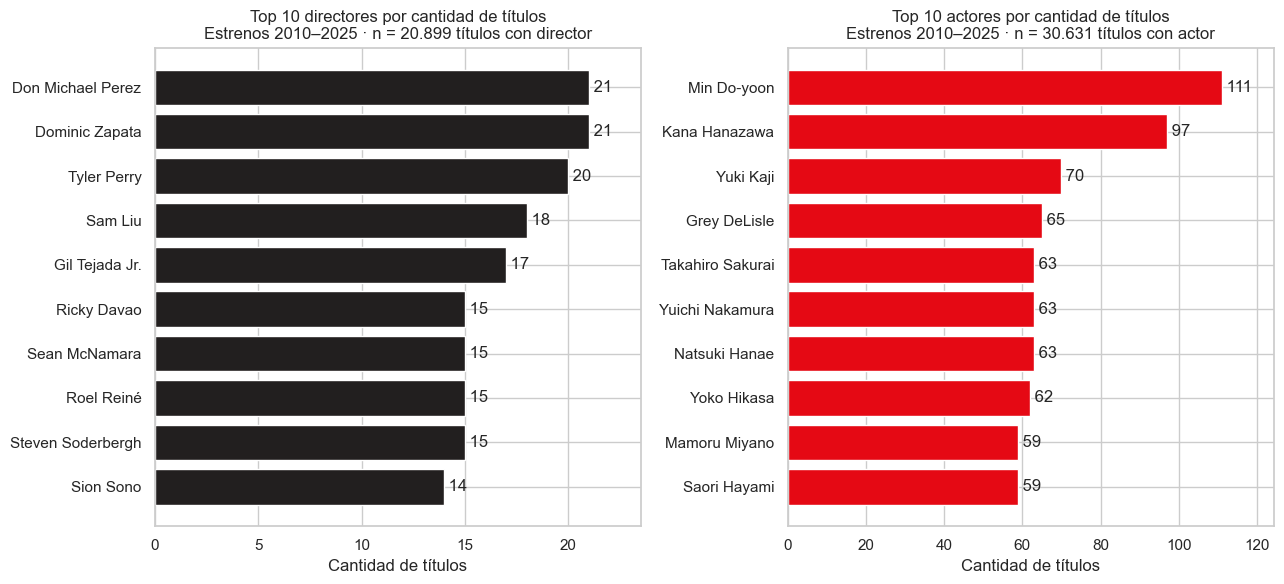

In [20]:
fig = ec.g_directores_actores(df)
plt.show()

**Hallazgo:** la presencia de directores es baja y pareja (14-21 titulos cada uno; el campo tiene 34.7% de
nulos), mientras que entre los actores destacan Min Do-yoon (111 titulos) y Kana Hanazawa (97).

## Sintesis — De los hallazgos del EDA al diseno del dashboard

| Pregunta de negocio | Hallazgo del EDA | Grafico recomendado para el dashboard | Por que |
|---|---|---|---|
| Evolucion del desempeno | Rating de peliculas sube sostenido; series estables | **Lineas** (rating promedio por ano, color por tipo) | Tendencia continua en el tiempo, comparando 2 series |
| Volumen por genero | Drama/Comedia/Accion/Animacion concentran el catalogo | **Barras horizontales** (top 10 generos) | Comparar magnitudes con etiquetas largas |
| Rating por genero | Volumen alto no implica mejor rating | **Barras agrupadas** (genero x tipo) | Comparar metrica cuantitativa entre categoria y sub-categoria |
| Rating vs. popularidad | Relacion positiva debil (Spearman 0.21; Pearson 0.03); el scatter revela un piso/techo real | **Dispersion (scatter)** | Un coeficiente de correlacion por si solo oculta patrones no lineales; el scatter los muestra |
| Distribucion geografica | 5 paises concentran la produccion | **Mapa + barras horizontales** | Percepcion espacial inmediata para audiencia ejecutiva |
| Retorno financiero | ROI mediano (ingresos / presupuesto) dispar por genero, con outliers | **Boxplot** (o barras de mediana en Power BI) | Evita que outliers financieros distorsionen el mensaje |
| Composicion del catalogo | 50/50 peliculas y series | **Circular (pie)** | Solo apropiado por ser 2 categorias que suman 100% |

**Conclusion:** el dashboard en Power BI reutiliza directamente estos mismos
tipos de grafico, porque cada eleccion ya fue
validada aqui contra la naturaleza real de los datos, no elegida a priori.

## Limitaciones de los datos

- **Muestra, no volumen real:** hay ~1.000 peliculas y ~1.000 series por ano de estreno (2010-2025); el dataset es una muestra estratificada y no sirve para medir el volumen real de estrenos.
- **`rating` = `vote_average`:** es un puntaje 0-10 promedio de votos (tipo TMDB), no una clasificacion de audiencia (G, PG-13...).
- **`duration`:** sin informacion util (100 % nulo en peliculas; "1 Seasons" en el 100 % de las series).
- **Financieros:** solo 3.386 de 16.000 peliculas (21 %) tienen presupuesto >= 1 M USD e ingresos validos; el ROI no aplica a series ni es extrapolable a todo el catalogo.
- **Sin genero / sin pais:** 974 series y 107 peliculas sin genero informado; 2.261 titulos sin pais. Se mantienen en el catalogo y se excluyen de los rankings correspondientes.
- **Taxonomias distintas:** el mapeo de generos entre peliculas y series es una decision de este proyecto (`src/genre_map.py`); algunos generos solo existen en un tipo (Thriller, Horror, Romance en peliculas; Reality, Talk, Soap, News en series).
- **Generos multiples:** con la tabla puente un titulo cuenta en todos sus generos; los conteos por genero no suman el total de titulos.
- **Correlacion:** la relacion rating-popularidad es debil y no lineal (Spearman 0.21; Pearson 0.03).